# Phase 0 - Loading the pretrained SEN2SR model

Before doing anything with our dataset, we want to make sure the original SEN2SR model works on this laptop.

Plan for this notebook:
1. Download the pretrained model and load it
2. Run it on the example image that comes with the model
3. Compare it with simple bicubic upscaling
4. Look inside the model (it has an FFT "hard constraint" at the end)
5. Try it on one image from our SEN2NAIP dataset

In [13]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import mlstac
import rasterio

In [14]:
# Mac with M-series chip -> "mps" uses the GPU
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)
print("torch version:", torch.__version__)

device: mps
torch version: 2.14.1


## 1. Download the model

SEN2SR has a few versions. Our data has 4 bands (Red, Green, Blue, NIR) at 10 m, so the matching one is **SEN2SRLite NonReference_RGBN_x4** (10 m → 2.5 m, so 4x bigger).

In [15]:
model_dir = "model/SEN2SRLite_RGBN_x4"

if not os.path.exists(model_dir):
    mlstac.download(
        file="https://huggingface.co/tacofoundation/sen2sr/resolve/main/SEN2SRLite/NonReference_RGBN_x4/mlm.json",
        output_dir=model_dir,
    )

print(os.listdir(model_dir))

['model.safetensor', 'hard_constraint.safetensor', 'example_data.safetensor', 'mlm.json', 'load.py']


In [16]:
model = mlstac.load(model_dir).compiled_model(device=device)
print(model)

SRModelWithConstraint(
  (sr_model): CNNSR(
    (conv_1): Conv3XC(
      (sk): Conv2d(4, 24, kernel_size=(1, 1), stride=(1, 1))
      (conv): Sequential(
        (0): Conv2d(4, 8, kernel_size=(1, 1), stride=(1, 1))
        (1): Conv2d(8, 48, kernel_size=(3, 3), stride=(1, 1))
        (2): Conv2d(48, 24, kernel_size=(1, 1), stride=(1, 1))
      )
      (eval_conv): Conv2d(4, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (blocks): ModuleList(
      (0-5): 6 x SPAB(
        (c1_r): Conv3XC(
          (sk): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1))
          (conv): Sequential(
            (0): Conv2d(24, 48, kernel_size=(1, 1), stride=(1, 1))
            (1): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1))
            (2): Conv2d(48, 24, kernel_size=(1, 1), stride=(1, 1))
          )
          (eval_conv): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
        (c2_r): Conv3XC(
          (sk): Conv2d(24, 24, kernel_size=(1, 1), stri

In [17]:
total_params = sum(p.numel() for p in model.parameters())
print("total parameters:", total_params)

total parameters: 572336


The model card says ~472k parameters, but we get more. Looking at the code (`sen2sr/models/opensr_baseline/cnn.py`), every `Conv3XC` layer keeps its training convolutions **and** a merged 3x3 `eval_conv`, so some weights are stored twice. Still a very small model (a few MB).

## 2. Run it on the example image

In [18]:
lr, hr = mlstac.load(model_dir).example_data()

print("LR shape:", lr.shape)
print("HR shape:", hr.shape)
print("LR min / max:", lr.min().item(), lr.max().item())

LR shape: torch.Size([1, 4, 128, 128])
HR shape: torch.Size([1, 4, 512, 512])
LR min / max: 0.018699999898672104 0.9983999729156494


Shape is (batch, bands, height, width). Values are between 0 and 1 → this is **reflectance** (Sentinel-2 numbers divided by 10000).

In [19]:
with torch.no_grad():
    sr = model(lr.to(device)).cpu()

print("SR shape:", sr.shape)

SR shape: torch.Size([1, 4, 512, 512])


128 x 128 went in, 512 x 512 came out → 4x upscaling works. Let's look at it. The first 3 bands are R, G, B so we can plot them as a normal colour image.

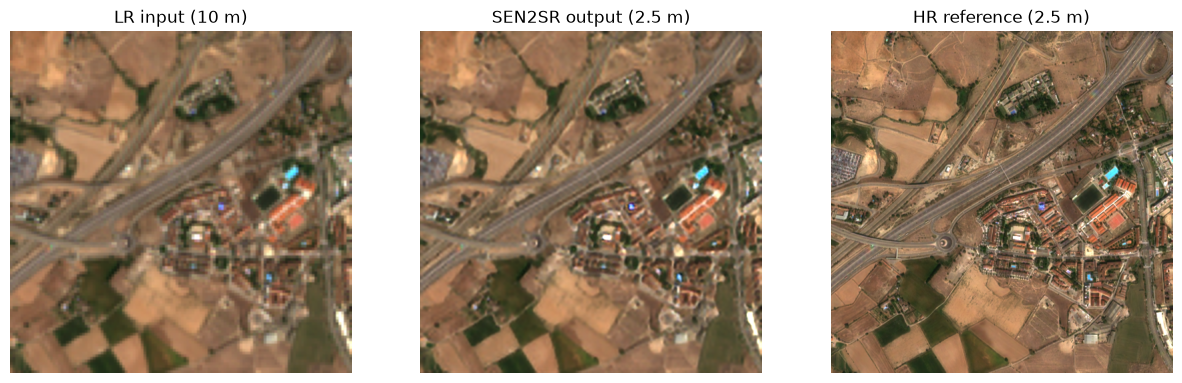

In [20]:
def show_rgb(img, title=""):
    # img: numpy array (bands, H, W) -> plot bands 0,1,2 as RGB
    rgb = img[:3].transpose(1, 2, 0)
    plt.imshow(np.clip(rgb * 3, 0, 1))   # *3 to make it brighter, reflectance values are small
    plt.title(title)
    plt.axis("off")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); show_rgb(lr[0].numpy(), "LR input (10 m)")
plt.subplot(1, 3, 2); show_rgb(sr[0].numpy(), "SEN2SR output (2.5 m)")
plt.subplot(1, 3, 3); show_rgb(hr[0].numpy(), "HR reference (2.5 m)")
plt.show()

Hard to see the difference at full size. Zooming into a small part:

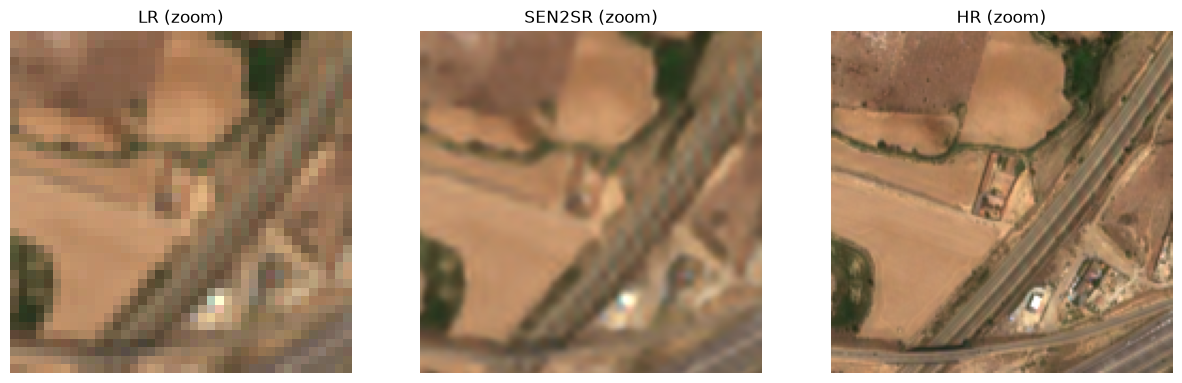

In [21]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); show_rgb(lr[0, :, 20:60, 20:60].numpy(), "LR (zoom)")
plt.subplot(1, 3, 2); show_rgb(sr[0, :, 80:240, 80:240].numpy(), "SEN2SR (zoom)")
plt.subplot(1, 3, 3); show_rgb(hr[0, :, 80:240, 80:240].numpy(), "HR (zoom)")
plt.show()

## 3. Compare with bicubic

Bicubic interpolation is the simplest way to make an image 4x bigger. If SEN2SR is useful, it should beat bicubic.

Metric: **PSNR** (higher = closer to the HR image). Values are reflectance in 0-1, so the max value is 1.

In [22]:
def psnr(a, b):
    mse = torch.mean((a - b) ** 2)
    return (10 * torch.log10(1 / mse)).item()

bicubic = F.interpolate(lr, scale_factor=4, mode="bicubic")
print("bicubic shape:", bicubic.shape)

print("PSNR bicubic:", round(psnr(bicubic, hr), 2), "dB")
print("PSNR SEN2SR :", round(psnr(sr, hr), 2), "dB")

bicubic shape: torch.Size([1, 4, 512, 512])
PSNR bicubic: 33.06 dB
PSNR SEN2SR : 33.35 dB


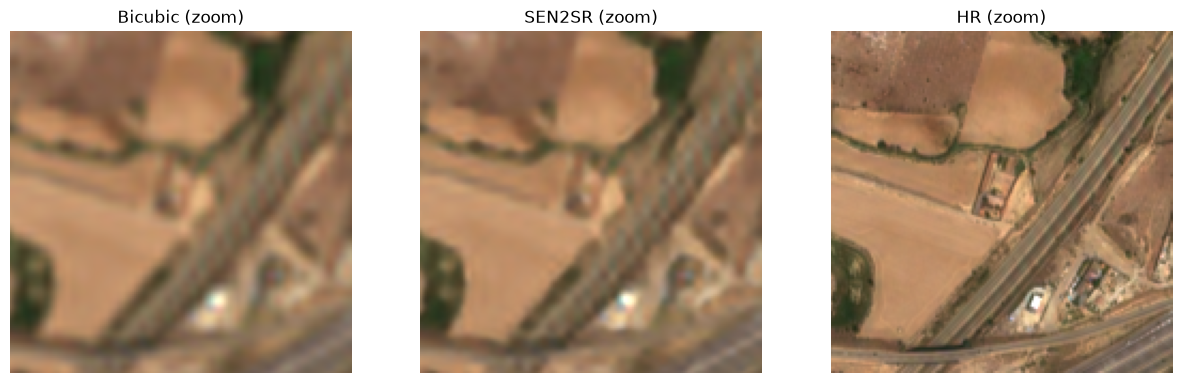

In [23]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); show_rgb(bicubic[0, :, 80:240, 80:240].numpy(), "Bicubic (zoom)")
plt.subplot(1, 3, 2); show_rgb(sr[0, :, 80:240, 80:240].numpy(), "SEN2SR (zoom)")
plt.subplot(1, 3, 3); show_rgb(hr[0, :, 80:240, 80:240].numpy(), "HR (zoom)")
plt.show()

SEN2SR is a bit better than bicubic on this image and looks sharper.

## 4. What is inside the model?

Printing the model showed two parts: `sr_model` (the CNN) and `hard_constraint`. From the sen2sr source code (`nonreference.py` and `models/tricks.py`) the forward pass is:

```
sr  = cnn(lr)                  # CNN makes a 4x image
sr  = clamp(sr, min=0)         # no negative values
out = hard_constraint(lr, sr)  # FFT step
```

The hard constraint:
1. makes a bicubic version of the LR image
2. takes the FFT (frequency domain) of both the bicubic image and the CNN output
3. keeps the **low frequencies from bicubic** and the **high frequencies from the CNN**, using a mask
4. inverse FFT back to an image

So the CNN is only allowed to add fine details. The big shapes and colours always come from the real Sentinel-2 image. Let's look at the mask.

mask shape: torch.Size([512, 512])
mask min / max: 5.831456237759119e-24 1.0


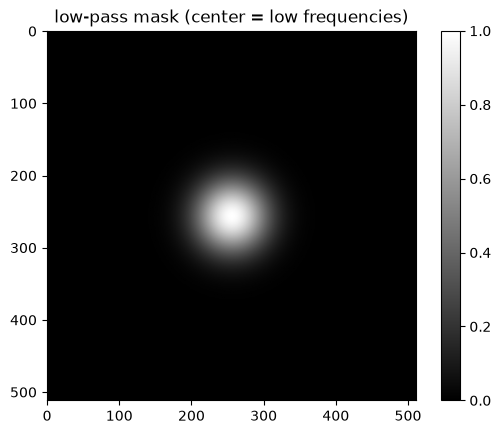

In [24]:
mask = model.hard_constraint.low_pass_mask.cpu()
print("mask shape:", mask.shape)
print("mask min / max:", mask.min().item(), mask.max().item())

plt.imshow(mask, cmap="gray")
plt.colorbar()
plt.title("low-pass mask (center = low frequencies)")
plt.show()

It is a smooth blob, not a sharp circle. Let's plot one row through the centre.

The LR image is 128 px, so in the 512 x 512 spectrum the highest frequency the LR image can contain is at distance 512 / 2 / 4 = **64** from the centre (Nyquist frequency of the LR image).

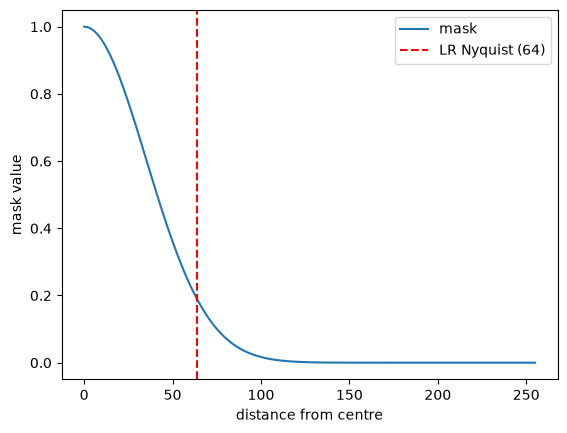

mask at 32: 0.6583891
mask at 64: 0.18790163
mask at 96: 0.023245756


In [25]:
center_row = mask[256, 256:].numpy()   # from the centre to the right edge
distance = np.arange(len(center_row))

plt.plot(distance, center_row, label="mask")
plt.axvline(64, color="red", linestyle="--", label="LR Nyquist (64)")
plt.xlabel("distance from centre")
plt.ylabel("mask value")
plt.legend()
plt.show()

print("mask at 32:", center_row[32])
print("mask at 64:", center_row[64])
print("mask at 96:", center_row[96])

This looks like a Gaussian: exp(-d² / (2σ²)). We can get σ from one point, e.g. d = 32:

σ = sqrt( -d² / (2 · ln(mask)) )

sigma = 35.0
max difference between mask and gaussian: 3.244440283101113e-08


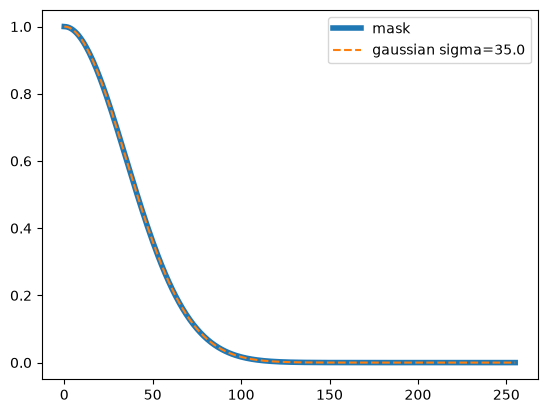

In [26]:
d = 32
sigma = np.sqrt(-d**2 / (2 * np.log(center_row[d])))
print("sigma =", sigma)

gaussian = np.exp(-distance**2 / (2 * sigma**2))
print("max difference between mask and gaussian:", np.abs(gaussian - center_row).max())

plt.plot(distance, center_row, label="mask", linewidth=4)
plt.plot(distance, gaussian, "--", label=f"gaussian sigma={sigma:.1f}")
plt.legend()
plt.show()

It is exactly a Gaussian with **σ = 35**.

Important for later (Phase 3, FFT idea):
- at the LR Nyquist (64) the mask is only ~0.19, so it is a **soft** mix, not a hard cutoff
- below 64, the output is a mix of bicubic + CNN
- above ~96, almost everything comes from the CNN

So our own FFT step later must do something **different** from this, otherwise it is just repeating what SEN2SR already does.

Quick experiment: what does the CNN give **without** the hard constraint?

In [27]:
with torch.no_grad():
    cnn_only = model.sr_model(lr.to(device)).cpu()

print("PSNR CNN only (no hard constraint):", round(psnr(cnn_only, hr), 2), "dB")
print("PSNR full SEN2SR                  :", round(psnr(sr, hr), 2), "dB")

# does the output still match the input when we shrink it back to 10 m?
print("LR consistency CNN only:", round(psnr(F.avg_pool2d(cnn_only, 4), lr), 2), "dB")
print("LR consistency SEN2SR  :", round(psnr(F.avg_pool2d(sr, 4), lr), 2), "dB")

PSNR CNN only (no hard constraint): 33.04 dB
PSNR full SEN2SR                  : 33.35 dB
LR consistency CNN only: 44.61 dB
LR consistency SEN2SR  : 52.3 dB


## 5. Try it on our own data

Our dataset is in `sen2naip/cross-sensor/`. Every folder has `lr.tif`, `hr.tif` and `metadata.json`.

In [28]:
folder = "sen2naip/cross-sensor/ROI_0000"
print(os.listdir(folder))

with rasterio.open(folder + "/lr.tif") as f:
    my_lr = f.read()
    print("LR:", my_lr.shape, my_lr.dtype, "min", my_lr.min(), "max", my_lr.max())
    print("LR pixel size:", f.res, "CRS:", f.crs)

with rasterio.open(folder + "/hr.tif") as f:
    my_hr = f.read()
    print("HR:", my_hr.shape, my_hr.dtype, "min", my_hr.min(), "max", my_hr.max())
    print("HR pixel size:", f.res)

['lr.tif', 'metadata.json', 'hr.tif']
LR: (4, 121, 121) int32 min 72 max 2469
LR pixel size: (10.0, 10.0) CRS: EPSG:32613
HR: (4, 484, 484) uint8 min 22 max 214
HR pixel size: (2.5, 2.5)


Things to notice:
- LR values are in the thousands → Sentinel-2 reflectance x 10000. The model wants 0-1, so we **divide by 10000**.
- HR is uint8 (0-255) → NAIP aerial photo, a different unit. Not needed for running the model, but we must deal with it before comparing (Phase 1).
- LR is **121 x 121**, but the model was made for **128 x 128**.

Let's just try to run it:

In [29]:
x = torch.tensor(my_lr / 10000, dtype=torch.float32).clamp(min=0).unsqueeze(0)   # add batch dimension
print("input shape:", x.shape)

try:
    with torch.no_grad():
        out = model(x.to(device))
    print("worked:", out.shape)
except Exception as e:
    print("ERROR:", e)

input shape: torch.Size([1, 4, 121, 121])
ERROR: The size of tensor a (484) must match the size of tensor b (512) at non-singleton dimension 3


It fails. The CNN gives 484 x 484, but the FFT mask is fixed at 512 x 512, so they can't be multiplied. (The `sen2sr.predict_large` helper has the same problem for images smaller than 128.)

Fix: **pad** the 121 x 121 image to 128 x 128, run the model, then cut the output back to 484 x 484.

Which padding? Test on the example image: cut it to 121, pad it back, and compare with the output from the full 128 image (where the model saw real pixels instead of padding).

In [30]:
small = lr[:, :, :121, :121]
print("small:", small.shape)

with torch.no_grad():
    reference = model(lr.to(device)).cpu()[:, :, :484, :484]

for mode in ["constant", "reflect", "replicate"]:
    padded = F.pad(small, (0, 7, 0, 7), mode=mode)   # (left, right, top, bottom)
    with torch.no_grad():
        out = model(padded.to(device)).cpu()[:, :, :484, :484]
    print(mode, "padded:", padded.shape, "-> PSNR vs real context:", round(psnr(out, reference), 2), "dB")

small: torch.Size([1, 4, 121, 121])
constant padded: torch.Size([1, 4, 128, 128]) -> PSNR vs real context: 41.7 dB
reflect padded: torch.Size([1, 4, 128, 128]) -> PSNR vs real context: 57.46 dB
replicate padded: torch.Size([1, 4, 128, 128]) -> PSNR vs real context: 59.85 dB


`replicate` (repeat the edge pixels) is closest, so we use that. Putting it in a small function:

In [31]:
def super_resolve(x):
    # x: (batch, 4, H, W) with H, W <= 128
    h, w = x.shape[2], x.shape[3]
    x = F.pad(x, (0, 128 - w, 0, 128 - h), mode="replicate")
    with torch.no_grad():
        out = model(x.to(device)).cpu()
    return out[:, :, :h * 4, :w * 4]

my_sr = super_resolve(x)
print("output shape:", my_sr.shape)
print("min / max:", my_sr.min().item(), my_sr.max().item())

output shape: torch.Size([1, 4, 484, 484])
min / max: 0.006825266405940056 0.257202684879303


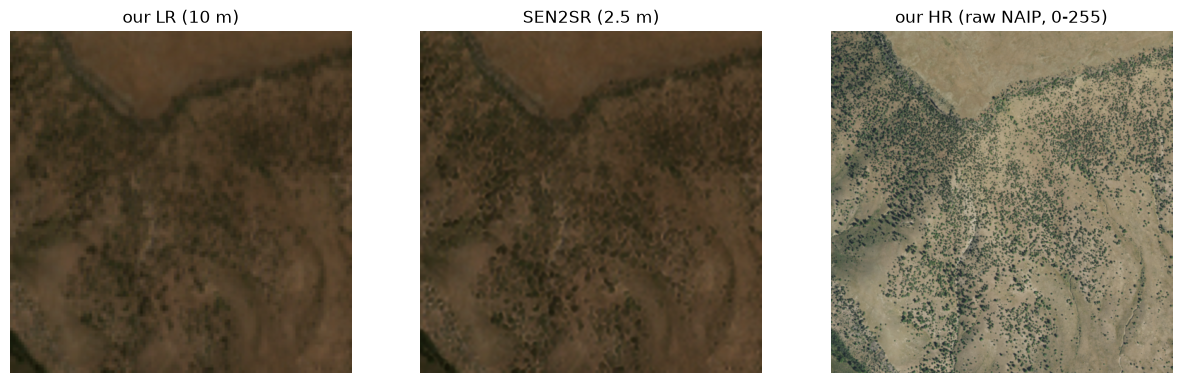

In [32]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); show_rgb(x[0].numpy(), "our LR (10 m)")
plt.subplot(1, 3, 2); show_rgb(my_sr[0].numpy(), "SEN2SR (2.5 m)")
plt.subplot(1, 3, 3)
plt.imshow(my_hr[:3].transpose(1, 2, 0)); plt.title("our HR (raw NAIP, 0-255)"); plt.axis("off")
plt.show()

Works on our data. The colours of the HR look different because it is raw NAIP values (handled in Phase 1).

## Speed

In [33]:
batch = torch.rand(16, 4, 128, 128)

start = time.time()
for i in range(5):
    with torch.no_grad():
        model(batch.to(device))
if device == "mps":
    torch.mps.synchronize()
seconds = (time.time() - start) / (5 * 16)

print(f"{seconds * 1000:.1f} ms per image on {device}")
print(f"whole dataset (2851 images) ~ {seconds * 2851:.0f} seconds")

11.4 ms per image on mps
whole dataset (2851 images) ~ 32 seconds


## Quick checks

In [34]:
assert sr.shape == (1, 4, 512, 512)
assert my_sr.shape == (1, 4, 484, 484)
assert not torch.isnan(my_sr).any()
assert psnr(sr, hr) > psnr(bicubic, hr)          # SEN2SR better than bicubic on the example
assert abs(sigma - 35) < 0.1                      # mask is the gaussian we found
print("all checks passed")

all checks passed


## What we learned

- The pretrained **SEN2SRLite RGBN x4** model loads and runs on the Mac GPU (mps), well under a minute for the whole dataset.
- Input: 4 bands (R, G, B, NIR), reflectance 0-1, 128 x 128 → output 512 x 512.
- On the example image SEN2SR beats bicubic (higher PSNR, sharper).
- The model ends with an **FFT hard constraint**: a Gaussian low-pass mask (σ = 35) mixes low frequencies from bicubic with high frequencies from the CNN. It is a soft mix, not a hard cutoff at the LR Nyquist (64). Our FFT idea in Phase 3 must be different from this.
- Without the hard constraint, the CNN alone is worse (lower PSNR, and much worse agreement with the LR input), so the constraint is doing useful work.
- Our tiles are **121 x 121**, which crashes the model → pad to 128 with `replicate`, then crop to 484.
- Our HR images are 0-255 NAIP values, not reflectance → to fix in Phase 1 before computing any metric.